<a href="https://colab.research.google.com/github/TotonhoMilk/IA_1/blob/main/Marco_1_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p style="text-align:right" >
    <a href="https://www.iesb.br/home/" target="_blank">
    <img src="https://www.iesb.br/content/themes/iesb-chleba-themosis/assets/imagens/logo.png" width="100"/>
    </a>
</p>

# Inteligência Artificial - Marco 1

**Alunos:**
* Alexandre Vieira Silva <br>
* Antônio Alexandre Cavalcante Leite<br>
* Carlos Eduardo Sousa Barcelos<br>

**Docente:** Prof. Rodrigo Gonçalves Pinto<br>
**Ambiente:** Google Colab

---

No Marco 1 foi realizado os modelos de buscas apresentados nos Laboratórios, com ênfase no A* com heurística própria, e a comparação numérica entre os argumentos, comprovando a admissibilidade da heurística

---

O projeto escolhido foi a entrega de mercadorias por Drones na região de Brasília-DF. A Asa Sul foi a área inicial delimitada.

#**PREPARANDO O AMBIENTE**
Instalação das bibliotecas necessárias para funcionamento do ambiente.

In [ ]:
# !pip install pandas numpy       <- descomente esta linha só se der erro.
# !pip install networkX

#**IMPORTANDO AS BIBLIOTECAS E CHECANDO AS VERSÕES**

Objetivo desta célula: descobrir em que máquina e em que versão do
Python o nosso código está rodando. É a primeira coisa que se checa
quando algo dá errado ("funciona na minha máquina" costuma ser um
problema de versão diferente).
Importamos as duas bibliotecas centrais da disciplina e conferimos
suas versões. Se alguma linha der erro, é sinal de que a biblioteca
não está instalada — e aí o comando comentado abaixo resolve.

In [ ]:
import sys        # módulo com informações sobre o interpretador Python
import platform   # módulo com informações sobre o sistema operacional
import numpy as np    # "as np" cria um APELIDO: escreveremos np em vez de numpy
import pandas as pd   # idem para pandas -> pd
import math
import matplotlib.pyplot as plt
import networkx as nx
import heapq
import itertools
from collections import deque


# sys.version é um texto longo, algo como "3.11.8 (main, Feb 2024) [GCC 11]".
# O método .split() quebra esse texto em pedaços separados por espaço e
# devolve uma lista; [0] pega o primeiro pedaço, que é só o número da versão.
versao_python = sys.version.split()[0]

# platform.system() devolve o nome do sistema ("Linux", "Windows", "Darwin").
# platform.release() devolve a versão do sistema.
sistema = platform.system()
versao_sistema = platform.release()

# A função print() exibe valores na tela. Quando passamos vários valores
# separados por vírgula, o Python os imprime lado a lado, separados por espaço.
print("Versão do Python:", versao_python)
print("Sistema:", sistema, versao_sistema)
print()

# Todo módulo bem construído guarda a própria versão no atributo __version__.
# Os dois underscores de cada lado indicam um atributo "especial" do Python.
print("numpy :", np.__version__)
print("pandas:", pd.__version__)

Versão do Python: 3.13.16
Sistema: Linux 6.6.122+

numpy : 2.1.3
pandas: 2.2.3


#**OBTENDO OS DRONEPORTOS**
Em consulta a Secretaria de Estado de Desenvolvimento Urbano e
Habitação - SEDUH foi realizado um estudo em cada quadra do Setor Asa
Sul do Plano Piloto de Brasília, visando o espaço mais adequado para
pouso de drones no interior das quadras.
As coordenadas apresentadas estão no formato UTM (Universal Transversa de Mercador) que formam um sistema de localização em plano
cartesiano que usa metros como unidade de medida para definir posições
na Terra

In [ ]:
MAPA_COORDENADA = {
    "central": "23S 189581 8248262", # Central de distribuição --> 608 Sul
    "sqs_302": "23S 190135 8250803",
    "sqs_102": "23S 190436 8250690",
    "sqs_202": "23S 190696 8250401",
    "sqs_402": "23S 191073 8250270",
    "sqs_303": "23S 189957 8250570",
    "sqs_103": "23S 190197 8250476",
    "sqs_203": "23S 190510 8250138",
    "sqs_403": "23S 190867 8249959",
    "sqs_304": "23S 189650 8250336",
    "sqs_104": "23S 190018 8250101",
    "sqs_204": "23S 190293 8249900",
    "sqs_404": "23S 190521 8249662",
    "sqs_305": "23S 189482 8250094",
    "sqs_105": "23S 189678 8249800",
    "sqs_205": "23S 190045 8249543",
    "sqs_405": "23S 190244 8249419",
    "sqs_306": "23S 189329 8249816",
    "sqs_106": "23S 189517 8249596",
    "sqs_206": "23S 189717 8249312",
    "sqs_406": "23S 190065 8249117",
    "sqs_307": "23S 189014 8249644",
    "sqs_107": "23S 189232 8249415",
    "sqs_207": "23S 189502 8249033",
    "sqs_407": "23S 189754 8248847",
    "sqs_308": "23S 188813 8249429",
    "sqs_108": "23S 188905 8249230",
    "sqs_208": "23S 189242 8248813",
    "sqs_408": "23S 189298 8248589",
    "sqs_309": "23S 188398 8249191",
    "sqs_109": "23S 188682 8248971",
    "sqs_209": "23S 188928 8248583",
    "sqs_409": "23S 188950 8248343",
    "sqs_310": "23S 188252 8248953",
    "sqs_110": "23S 188409 8248715",
    "sqs_210": "23S 188725 8248384",
    "sqs_410": "23S 188949 8248170",
    "sqs_311": "23S 187886 8248875",
    "sqs_111": "23S 188075 8248512",
    "sqs_211": "23S 188346 8248191",
    "sqs_411": "23S 188497 8247974",
    "sqs_312": "23S 187526 8248555",
    "sqs_112": "23S 187765 8248243",
    "sqs_212": "23S 188017 8247862",
    "sqs_412": "23S 188193 8247693",
    "sqs_313": "23S 187216 8248380",
    "sqs_113": "23S 187517 8248051",
    "sqs_213": "23S 187734 8247734",
    "sqs_413": "23S 188004 8247422",
    "sqs_314": "23S 186990 8248071",
    "sqs_114": "23S 187229 8248012",
    "sqs_214": "23S 187530 8247506",
    "sqs_414": "23S 187651 8247291",
    "sqs_315": "23S 186749 8247880",
    "sqs_115": "23S 186966 8247683",
    "sqs_215": "23S 187187 8247304",
    "sqs_415": "23S 187313 8247049",
    "sqs_316": "23S 186412 8247748",
    "sqs_116": "23S 186599 8247435",
    "sqs_216": "23S 186873 8247112",
    "sqs_416": "23S 187138 8246884",
}

print(f"Quantidade de Dronepontos: {len(MAPA_COORDENADA)}")

Quantidade de Dronepontos: 61


#**AJUSTANDO OS DADOS**
Nesta célula, as coordenadas apresentadas são trabalhadas para números
inteiros em um dicionário com a quadra e a tuplas de coordenada.

In [ ]:
COORD = {}
for drone in MAPA_COORDENADA:
    x = int(MAPA_COORDENADA[drone].split()[1])
    y = int(MAPA_COORDENADA[drone].split()[2])
    COORD[drone] = (x, y)

print("+------------------------------+")
print("|         DRONEPONTOS          |")
print("+------------------------------+")
print("|                              |")

cont = 0
for droneporto, coordenada in COORD.items():
    if droneporto == "central":
        print(f"| {droneporto} -> {coordenada} |")
        print("|                              |")
    elif cont == 3:
        print(f"| {droneporto} -> {coordenada} |")
        print("|                              |")
        cont = 0
    else:
        print(f"| {droneporto} -> {coordenada} |")
        cont += 1

print("+------------------------------+")
print()

+------------------------------+
|         DRONEPONTOS          |
+------------------------------+
|                              |
| central -> (189581, 8248262) |
|                              |
| sqs_302 -> (190135, 8250803) |
| sqs_102 -> (190436, 8250690) |
| sqs_202 -> (190696, 8250401) |
| sqs_402 -> (191073, 8250270) |
|                              |
| sqs_303 -> (189957, 8250570) |
| sqs_103 -> (190197, 8250476) |
| sqs_203 -> (190510, 8250138) |
| sqs_403 -> (190867, 8249959) |
|                              |
| sqs_304 -> (189650, 8250336) |
| sqs_104 -> (190018, 8250101) |
| sqs_204 -> (190293, 8249900) |
| sqs_404 -> (190521, 8249662) |
|                              |
| sqs_305 -> (189482, 8250094) |
| sqs_105 -> (189678, 8249800) |
| sqs_205 -> (190045, 8249543) |
| sqs_405 -> (190244, 8249419) |
|                              |
| sqs_306 -> (189329, 8249816) |
| sqs_106 -> (189517, 8249596) |
| sqs_206 -> (189717, 8249312) |
| sqs_406 -> (190065, 8249117) |
|         

#**TRANFORMANDO OS DADOS EM UM GRAFO**
O intuito desta célula é tranformar as tuplas de coordenadas em um
grafo. Usando a biblioteca networkX no python, foi possível trabalhar
as tuplas para se obter um grafo, chamado de G.

In [ ]:
# 1. Tratar coordenadas (X, Y)
coords = {}
for nome, texto in MAPA_COORDENADA.items():
    _, x, y = texto.split()
    coords[nome] = (float(x), float(y))

# Função de distância física em metros
def obter_distancia(u, v):
    x1, y1 = coords[u]
    x2, y2 = coords[v]
    return math.hypot(x2 - x1, y2 - y1)


# 2. Inicializar Grafo
G = nx.Graph()
for nome, pos in coords.items():
    G.add_node(nome, pos=pos)

# 3. Regras estritas de Vizinhança Ortogonal (Sem Diagonais)
quadras = [n for n in coords.keys() if n != "central"]

for q in quadras:
    prefixo, num_str = q.split("_")
    faixa = int(num_str[0])  # Ex: 3, 1, 2 ou 4
    numero = int(num_str[1:])  # Ex: 02, 03... 16

    # A) Conexão Horizontal: Quadra seguinte na mesma faixa (ex: 102 <-> 103)
    vizinho_horiz = f"sqs_{faixa}{numero+1:02d}"
    if vizinho_horiz in coords:
        dist = obter_distancia(q, vizinho_horiz)
        G.add_edge(q, vizinho_horiz, weight=dist)

    # B) Conexão Vertical: Faixas vizinhas da mesma quadra (300 <-> 100 <-> 200 <-> 400)
    mapeamento_vertical = {3: [1], 1: [3, 2], 2: [1, 4], 4: [2]}
    for faixa_vizinha in mapeamento_vertical[faixa]:
        vizinho_vert = f"sqs_{faixa_vizinha}{numero:02d}"
        if vizinho_vert in coords:
            dist = obter_distancia(q, vizinho_vert)
            G.add_edge(q, vizinho_vert, weight=dist)

# 4. Conectar a Central à quadra mais próxima da faixa 200/400 (SQS 208 ou SQS 408)
central_vizinhos = ["sqs_408"]
for v in central_vizinhos:
    dist = obter_distancia("central", v)
    G.add_edge("central", v, weight=dist)

#**TRANSFORMANDO O GRAFO EM UM DICIONÁRIO**
Após a geração do grafo, nesta célula, foi realizado a transformação
em um dicionário de dicionário conforme as instruções no Laboratórios

In [ ]:
MAPA = {}

for no in G.nodes():
    MAPA[no] = {}
    for vizinho in G.neighbors(no):
        # Captura o peso (distância em metros) da aresta entre 'no' e 'vizinho'
        distancia = G[no][vizinho]["weight"]
        # Arredonda para 2 casas decimais (opcional)
        MAPA[no][vizinho] = round(distancia, 2)

for n in MAPA.items():
    print(n)

qtd_caminhos = sum(len(v) for v in MAPA.values()) // 2
print("\nEstradas no mapa:", qtd_caminhos)

('central', {'sqs_408': 432.46})
('sqs_302', {'sqs_303': 293.21, 'sqs_102': 321.51})
('sqs_102', {'sqs_302': 321.51, 'sqs_103': 320.81, 'sqs_202': 388.74})
('sqs_202', {'sqs_102': 388.74, 'sqs_203': 322.13, 'sqs_402': 399.11})
('sqs_402', {'sqs_202': 399.11, 'sqs_403': 373.04})
('sqs_303', {'sqs_302': 293.21, 'sqs_304': 386.01, 'sqs_103': 257.75})
('sqs_103', {'sqs_102': 320.81, 'sqs_303': 257.75, 'sqs_104': 415.53, 'sqs_203': 460.67})
('sqs_203', {'sqs_202': 322.13, 'sqs_103': 460.67, 'sqs_204': 322.08, 'sqs_403': 399.36})
('sqs_403', {'sqs_402': 373.04, 'sqs_203': 399.36, 'sqs_404': 455.99})
('sqs_304', {'sqs_303': 386.01, 'sqs_305': 294.6, 'sqs_104': 436.63})
('sqs_104', {'sqs_103': 415.53, 'sqs_304': 436.63, 'sqs_105': 454.09, 'sqs_204': 340.63})
('sqs_204', {'sqs_203': 322.08, 'sqs_104': 340.63, 'sqs_205': 434.69, 'sqs_404': 329.59})
('sqs_404', {'sqs_403': 455.99, 'sqs_204': 329.59, 'sqs_405': 368.48})
('sqs_305', {'sqs_304': 294.6, 'sqs_306': 317.32, 'sqs_105': 353.34})
('sqs_10

#**AUDITANDO O MAPA**
Duas verificações antes de confiar nos dados.

Variável:
   problemas -> lista que acumula as inconsistências encontradas

In [ ]:
problemas = []                      # a lista começa vazia: nenhum erro ainda

# .items() percorre o dicionário devolvendo o par (chave, valor) de cada vez.
for cidade, vizinhos in MAPA.items():
    for vizinho, distancia in vizinhos.items():

        # Verificação 1: a cidade vizinha existe como chave no mapa?
        if vizinho not in MAPA:
            problemas.append(f"{vizinho} aparece como vizinha mas não existe")

        # Verificação 2: a distância é a mesma nos dois sentidos?
        # .get() consulta com segurança: devolve None se a chave não existir,
        # em vez de interromper o programa com KeyError.
        elif MAPA[vizinho].get(cidade) != distancia:
            problemas.append(f"{cidade}-{vizinho}: assimetria de distância")

if problemas:
    print("Problemas encontrados:")
    for p in problemas:
        print("  -", p)
else:
    print(f"Mapa íntegro: {len(MAPA_COORDENADA)} dronepontos, {qtd_caminhos} estradas, todas simétricas.")

Mapa íntegro: 61 dronepontos, 102 estradas, todas simétricas.


#**CONSULTANDO O MAPA**
As três consultas que todo algoritmo de busca faz ao mapa.

In [ ]:
cidade_atual = "sqs_106"

# PERGUNTA 1 — "para onde eu posso ir a partir daqui?"
# list() converte as chaves em lista, só para imprimir de forma legível.
print("Vizinhos de", cidade_atual, "->", list(MAPA[cidade_atual].keys()))

# PERGUNTA 2 — "quanto custa cada uma dessas estradas?"
print("Custos              ->", MAPA[cidade_atual])

# PERGUNTA 3 — "quanto custa ir daqui para uma cidade específica?"
print("SQS 106             -> SQS 206:", MAPA["sqs_106"]["sqs_206"], "metros")

print()   # print() sem argumentos apenas pula uma linha

# O padrão que vai aparecer DENTRO de todos os algoritmos:
# percorrer os vizinhos e seus custos ao mesmo tempo, com .items().
# A f-string usa :16s para alinhar o nome em 16 caracteres, deixando
# a saída em colunas; :3d faz o mesmo com um número inteiro.
for vizinho, custo in MAPA[cidade_atual].items():
    print(f"  de {cidade_atual} para {vizinho:6s} custa {custo:3.2f} metros")

Vizinhos de sqs_106 -> ['sqs_105', 'sqs_306', 'sqs_107', 'sqs_206']
Custos              -> {'sqs_105': 259.88, 'sqs_306': 289.39, 'sqs_107': 337.62, 'sqs_206': 347.36}
SQS 106             -> SQS 206: 347.36 metros

  de sqs_106 para sqs_105 custa 259.88 metros
  de sqs_106 para sqs_306 custa 289.39 metros
  de sqs_106 para sqs_107 custa 337.62 metros
  de sqs_106 para sqs_206 custa 347.36 metros


#**CALCULANDO O CUSTO DO CAMINHO**
Custo do caminho --> custo_do_caminho(caminho) - recebe lista de cidades e devolve a soma dos custos de cada trecho percorrido.

In [ ]:
def custo_do_caminho(caminho):
    """Soma os custos de passo ao longo de uma lista de cidades.

    Parâmetro:
        caminho (list): lista de cidades em ordem, ex. ["sqs_302", "sqs_416"].

    Devolve:
        int: o custo total do caminho, em metros.
    """
    # Apague a linha abaixo e escreva sua solução.
    # return None
    custo = 0
    for i in range(len(caminho) - 1):
        custo += MAPA[caminho[i]][caminho[i + 1]]
    return custo

# ------------------- teste automático, não precisa alterar -------------------
rota_cntl_316_1 = [
    "central", "sqs_408", "sqs_208", "sqs_209", "sqs_210",
    "sqs_110", "sqs_111", "sqs_112", "sqs_113", "sqs_114",
    "sqs_314", "sqs_315", "sqs_316"
]

rota_cntl_316_2 = [
    "central", "sqs_408", "sqs_409", "sqs_410", "sqs_411",
    "sqs_412", "sqs_413", "sqs_414", "sqs_415", "sqs_416",
    "sqs_216", "sqs_116", "sqs_316"
]

resultado_1 = custo_do_caminho(rota_cntl_316_1)
resultado_2 = custo_do_caminho(rota_cntl_316_2)

if resultado_1 == 4115.63 and resultado_2 == 4439.17:
  print("Tudo Correto!")
  print("   Rota 1 de central a SQS 316:", resultado_1, "metros")
  print("   Rota 2 de central a SQS 316:", resultado_2, "metros")
else:
  print("Resultado incorreto!")
  print("   Rota 1 de central a SQS 316:", resultado_1, "metros")
  print("   Rota 2 de central a SQS 316:", resultado_2, "metros")

Tudo Correto!
   Rota 1 de central a SQS 316: 4115.63 metros
   Rota 2 de central a SQS 316: 4439.17 metros


#**DESENHANDO O MAPA**
Função desenha_mapa() que realiza a impressão do mapa usando a biblioteca matplotlib.<br>
Repare que o mapa não tem simetria porque os pontos foram escolhidos
no interior de cada quadra visando o melhor local de pouso.

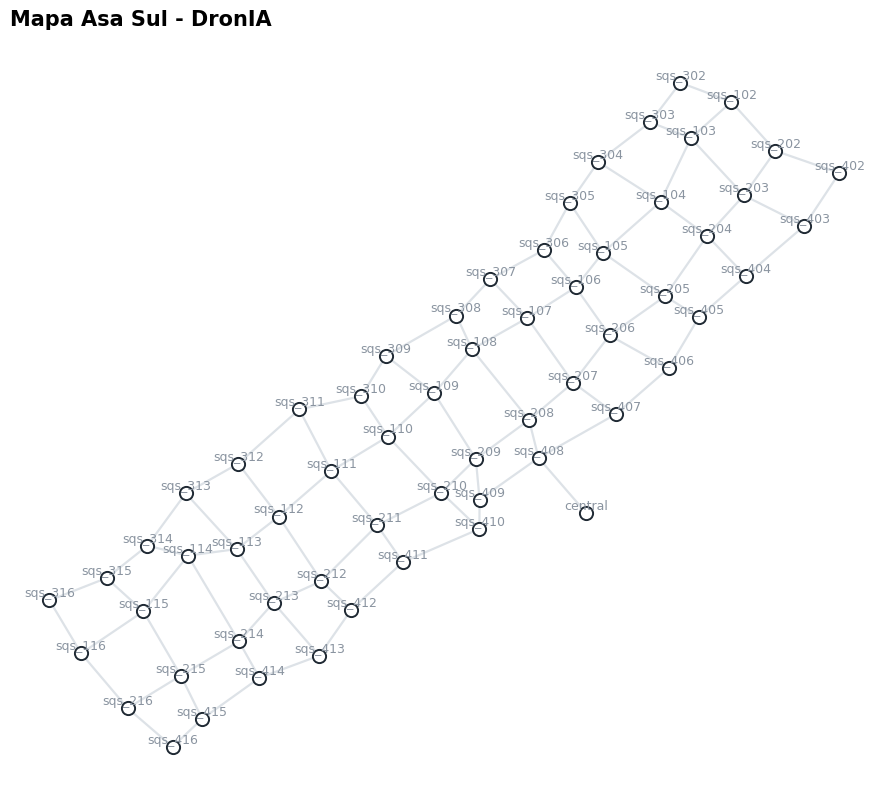

In [ ]:
VERMELHO_IESB = "#C8102E"


def desenhar_mapa(caminho=None, expandidos=None, titulo="Mapa Geral"):
    """Desenha o mapa; se receber um caminho, pinta-o em vermelho."""
    caminho = caminho or []          # "or []" evita erro quando vem None
    expandidos = expandidos or []

    fig, ax = plt.subplots(figsize=(13, 8))
    ax.set_aspect("equal")

    # 1) todas as estradas em cinza claro, ao fundo
    ja_desenhadas = set()
    for cidade, vizinhos in MAPA.items():
        for vizinho in vizinhos:
            # o par ordenado evita desenhar a mesma estrada duas vezes
            par = tuple(sorted([cidade, vizinho]))
            if par in ja_desenhadas:
                continue
            ja_desenhadas.add(par)
            x1, y1 = COORD[cidade]
            x2, y2 = COORD[vizinho]
            ax.plot([x1, x2], [y1, y2], color="#DDE2E7", lw=1.6, zorder=1)

    # 2) por cima, as estradas que fazem parte do caminho-solução.
    # zip(caminho, caminho[1:]) forma os pares consecutivos da lista:
    # ["A","B","C"] vira ("A","B") e ("B","C").
    for a, b in zip(caminho, caminho[1:]):
        x1, y1 = COORD[a]
        x2, y2 = COORD[b]
        ax.plot([x1, x2], [y1, y2], color=VERMELHO_IESB, lw=5, alpha=0.45,
                zorder=2)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(MAPA[a][b]), fontsize=10,
                color=VERMELHO_IESB, ha="center", va="center", zorder=5,
                bbox=dict(boxstyle="round,pad=0.2", fc="white",
                          ec=VERMELHO_IESB))

    # 3) as cidades
    for cidade, (x, y) in COORD.items():
        if cidade in expandidos:
            ordem = expandidos.index(cidade) + 1     # posição na expansão
            ax.scatter(x, y, s=330, color=VERMELHO_IESB, zorder=3)
            ax.text(x, y, str(ordem), fontsize=10, color="white", ha="center",
                    va="center", fontweight="bold", zorder=4)
        else:
            ax.scatter(x, y, s=90, color="white", edgecolors="#1F2933",
                       linewidths=1.4, zorder=3)
        destaque = cidade in caminho or cidade in expandidos
        ax.text(x, y + 18, cidade, fontsize=10 if destaque else 9,
                color="#1F2933" if destaque else "#8A94A0", ha="center",
                fontweight="bold" if destaque else "normal", zorder=6)

    ax.set_title(titulo, fontsize=15, fontweight="bold", loc="left")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


desenhar_mapa(titulo="Mapa Asa Sul - DronIA")

#**ESTRUTURANDO A CLASSE NÓ**
A estrutura NÓ.

Usamos uma classe com __slots__ para deixar explícitos os quatro
campos — e, de quebra, gastar menos memória, o que importa quando a
busca gera milhares de nós.

In [ ]:
class No:
    """Um nó da árvore de busca: estado + memória de como chegamos até ele."""

    __slots__ = ("estado", "pai", "acao", "g")

    def __init__(self, estado, pai=None, acao=None, g=0):
        self.estado = estado    # a cidade
        self.pai = pai          # o nó anterior (None se for a raiz)
        self.acao = acao        # a ação aplicada no pai
        self.g = g              # custo acumulado desde o início

    def __repr__(self):
        # __repr__ define o que aparece quando imprimimos o objeto.
        # Sem ele, o Python mostraria algo como <__main__.No object at 0x7f...>.
        return f"No({self.estado}, g={self.g})"

    def __lt__(self, outro):
        # __lt__ define o operador "<". O heapq (fila de prioridade) precisa
        # dele para desempatar quando duas prioridades forem iguais.
        return self.g < outro.g


# Montando uma cadeia de nós NA MÃO, para ver a estrutura funcionando.
raiz    = No("central")
n_408   = No("sqs_408",  pai= raiz,  acao="sqs_408",  g= 432.46)
n_208   = No("sqs_208",  pai=n_408,  acao="sqs_208",  g= 663.35)
n_209   = No("sqs_209",  pai=n_208,  acao="sqs_209",  g=1052.57)

print("O nó final:", n_209)
print("O pai dele:", n_209.pai)
print("O avô dele:", n_209.pai.pai)
print()
print("Custo acumulado até SQS 209:", n_209.g, "metros")
print("Conferindo na mão: 432.46 + 230.89 + 389.22 =", 432.46 + 230.89 + 389.22,
      "metros")

O nó final: No(sqs_209, g=1052.57)
O pai dele: No(sqs_208, g=663.35)
O avô dele: No(sqs_408, g=432.46)

Custo acumulado até SQS 209: 1052.57 metros
Conferindo na mão: 432.46 + 230.89 + 389.22 = 1052.57 metros


#**RECONSTRUINDO O CAMINHO**
Reconstrução do caminho: do nó-objetivo até a raiz, seguindo as quadras.

In [ ]:
def reconstruir_caminho(no):
    """Devolve a lista de estados da raiz até o nó recebido.

    Parâmetro:
        no (No): o nó final, normalmente o que satisfez o teste de objetivo.

    Devolve:
        list: as cidades em ordem, do início até o nó.
    """
    caminho = []                    # lista vazia para acumular os estados

    while no is not None:           # "is not None" para quando chegar na raiz
        caminho.append(no.estado)   # anota o estado do nó atual
        no = no.pai                 # sobe um nível na cadeia

    # Neste ponto a lista está de TRÁS PARA FRENTE: [Pitesti, ..., Arad].
    # A fatia [::-1] percorre a lista de ré e devolve uma cópia invertida.
    return caminho[::-1]


caminho_reconstruido = reconstruir_caminho(n_209)

print("Caminho reconstruído:", caminho_reconstruido)
print("Custo guardado no nó:", n_209.g, "metros")

# Reusando o TODO 1: o custo somado do caminho tem que bater com o g do nó.
if custo_do_caminho(caminho_reconstruido) is not None:
    print("Custo recalculado   :", custo_do_caminho(caminho_reconstruido),
          "metros")

Caminho reconstruído: ['central', 'sqs_408', 'sqs_208', 'sqs_209']
Custo guardado no nó: 1052.57 metros
Custo recalculado   : 1052.57 metros


#**REALIZANDO AS BUSCAS**

Etapa principal do Marco 1. Serão realizadas buscas:
* Busca em Largura;
* Busca de Custo Uniforme;
* Busca em Profundidade;
* Busca Gulosa;
* Busca A*


In [ ]:
# Variáveis que serão utilizadas nos testes das buscas

inicio = "central"
fim = "sqs_302"

#**BUSCA EM LARGURA**

Neste momento do Marco 1 se iniciam as buscas.
A primeira a ser trabalhada é a busca em largura

Todas as buscas serão realizadas a partir da central de distribuição até a SQS 302, por meio das variáveis "inicio" e "fim", a seguir:

In [ ]:
def busca_largura(inicio, objetivo):
    """Busca em largura em grafo.

    Parâmetros:
        inicio (str): cidade de partida.
        objetivo (str): cidade de destino.

    Devolve:
        tuple: (caminho, custo, nós expandidos, ordem de expansão).
    """
    fronteira = deque([No(inicio)])   # a fronteira começa com o nó inicial
    explorados = set()                # conjunto: consulta imediata
    na_fronteira = {inicio}           # espelho da fronteira, para consulta rápida
    ordem = []                        # registra a ordem das expansões

    while fronteira:                  # enquanto houver nós para examinar
        no = fronteira.popleft()      # retira o mais antigo: regra da fila
        na_fronteira.discard(no.estado)

        # Teste de objetivo NA REMOÇÃO, conforme a convenção da disciplina.
        if no.estado == objetivo:
            return reconstruir_caminho(no), no.g, len(ordem), ordem

        explorados.add(no.estado)     # marca como já expandido
        ordem.append(no.estado)

        for vizinho, custo in MAPA[no.estado].items():
            if vizinho in explorados or vizinho in na_fronteira:
                continue              # já visto: ignora e vai para o próximo

            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)

            fronteira.append(filho)

            na_fronteira.add(vizinho)

    return None, None, len(ordem), ordem


# ------------------- teste automático, não precisa alterar -------------------
cam_bfs, custo_bfs, exp_bfs, ordem_bfs = busca_largura(inicio, fim)

print(f"Custo: {custo_bfs:.2f} metros | Nós expandidos: {exp_bfs}")
print(f"\nCaminho: '{cam_bfs[0]}' até '{cam_bfs[-1]}'")
print(f"\nCaminho expandido: \n{cam_bfs}")

Custo: 4026.17 metros | Nós expandidos: 54

Caminho: 'central' até 'sqs_302'

Caminho expandido: 
['central', 'sqs_408', 'sqs_407', 'sqs_406', 'sqs_405', 'sqs_404', 'sqs_403', 'sqs_402', 'sqs_202', 'sqs_102', 'sqs_302']


#**VISUALIZANDO O QUE A BUSCA EM LARGURA FEZ**

Mapa de nós ilustrando a busca em largura.

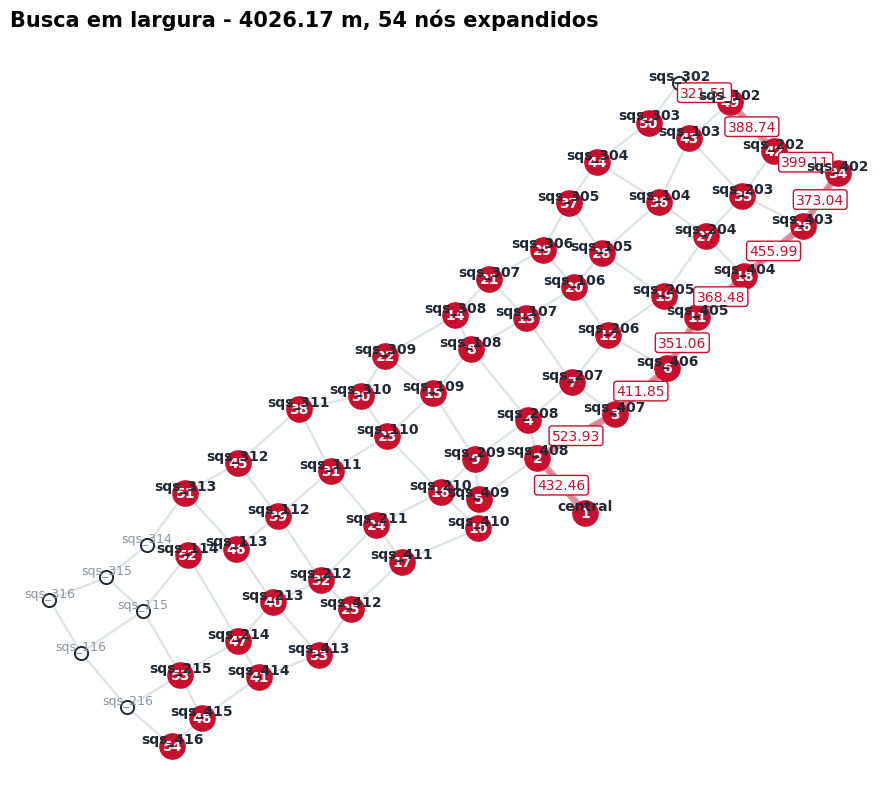

Ordem de expansão dos nós:
 1: central |  2: sqs_408 |  3: sqs_407 |  4: sqs_208 |  5: sqs_409 |  6: sqs_406 |  7: sqs_207 | 
 8: sqs_108 |  9: sqs_209 | 10: sqs_410 | 11: sqs_405 | 12: sqs_206 | 13: sqs_107 | 14: sqs_308 | 
15: sqs_109 | 16: sqs_210 | 17: sqs_411 | 18: sqs_404 | 19: sqs_205 | 20: sqs_106 | 21: sqs_307 | 
22: sqs_309 | 23: sqs_110 | 24: sqs_211 | 25: sqs_412 | 26: sqs_403 | 27: sqs_204 | 28: sqs_105 | 
29: sqs_306 | 30: sqs_310 | 31: sqs_111 | 32: sqs_212 | 33: sqs_413 | 34: sqs_402 | 35: sqs_203 | 
36: sqs_104 | 37: sqs_305 | 38: sqs_311 | 39: sqs_112 | 40: sqs_213 | 41: sqs_414 | 42: sqs_202 | 
43: sqs_103 | 44: sqs_304 | 45: sqs_312 | 46: sqs_113 | 47: sqs_214 | 48: sqs_415 | 49: sqs_102 | 
50: sqs_303 | 51: sqs_313 | 52: sqs_114 | 53: sqs_215 | 54: sqs_416 | 

In [ ]:
if cam_bfs:
    desenhar_mapa(
        caminho=cam_bfs,
        expandidos=ordem_bfs,
        titulo=f"Busca em largura - {custo_bfs:.2f} m, {exp_bfs} nós expandidos",
    )

print("Ordem de expansão dos nós:")
for count, n in enumerate(ordem_bfs, start=1):
    print(f"{count:2d}: {n} |", end=" ")
    if count % 7 == 0:
        print()

# **BUSCA DE CUSTO UNIFORME**

A seguir será realizada a função de busca de custo uniforme e o seu teste.

In [ ]:
def busca_custo_uniforme(inicio, objetivo):
    """Expande sempre o nó de menor custo acumulado g(n).

    Parâmetros:
        inicio (str): partida.
        objetivo (str): destino.

    Devolve:
        tuple: (caminho, custo, nós expandidos, ordem de expansão).
    """
    contador = itertools.count()      # gera 0, 1, 2, 3... para desempate
    fronteira = []
    heapq.heappush(fronteira, (0, next(contador), No(inicio)))
    explorados = set()
    ordem = []

    while fronteira:
        # heappop devolve a tupla inteira; "_" marca o que não vamos usar.
        _, _, no = heapq.heappop(fronteira)

        if no.estado == objetivo:
            return reconstruir_caminho(no), no.g, len(ordem), ordem

        # Um mesmo estado pode ter entrado várias vezes com custos diferentes.
        # Se já expandimos este estado, esta cópia é obsoleta: descartamos.
        if no.estado in explorados:
            continue

        explorados.add(no.estado)
        ordem.append(no.estado)

        for vizinho, custo in MAPA[no.estado].items():
            if vizinho in explorados:
                continue

            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)

            heapq.heappush(fronteira, (filho.g, next(contador), filho))

    return None, None, len(ordem), ordem

# ------------------- teste automático, não precisa alterar -------------------
cam_ucs, custo_ucs, exp_ucs, ordem_ucs = busca_custo_uniforme(inicio, fim)

print(f"Custo: {custo_ucs:.2f} metros | Nós expandidos: {exp_ucs}")
print(f"\nCaminho: '{cam_ucs[0]}' até '{cam_ucs[-1]}'")
print(f"\nCaminho expandido: \n{cam_ucs}")

Custo: 3284.06 metros | Nós expandidos: 52

Caminho: 'central' até 'sqs_302'

Caminho expandido: 
['central', 'sqs_408', 'sqs_208', 'sqs_207', 'sqs_206', 'sqs_106', 'sqs_306', 'sqs_305', 'sqs_304', 'sqs_303', 'sqs_302']


#**VISUALIZANDO O QUE A BUSCA DE CUSTO UNIFORME FEZ**

O ótimo, e o preço pago.

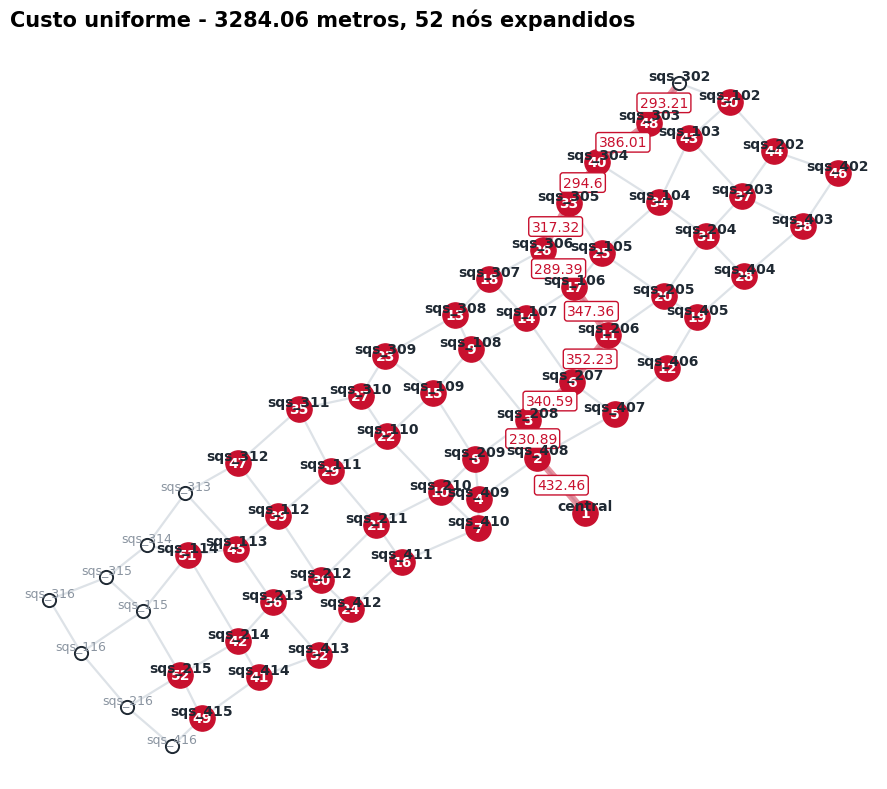

Ordem de expansão dos nós:
 1: central |  2: sqs_408 |  3: sqs_407 |  4: sqs_208 |  5: sqs_409 |  6: sqs_406 |  7: sqs_207 | 
 8: sqs_108 |  9: sqs_209 | 10: sqs_410 | 11: sqs_405 | 12: sqs_206 | 13: sqs_107 | 14: sqs_308 | 
15: sqs_109 | 16: sqs_210 | 17: sqs_411 | 18: sqs_404 | 19: sqs_205 | 20: sqs_106 | 21: sqs_307 | 
22: sqs_309 | 23: sqs_110 | 24: sqs_211 | 25: sqs_412 | 26: sqs_403 | 27: sqs_204 | 28: sqs_105 | 
29: sqs_306 | 30: sqs_310 | 31: sqs_111 | 32: sqs_212 | 33: sqs_413 | 34: sqs_402 | 35: sqs_203 | 
36: sqs_104 | 37: sqs_305 | 38: sqs_311 | 39: sqs_112 | 40: sqs_213 | 41: sqs_414 | 42: sqs_202 | 
43: sqs_103 | 44: sqs_304 | 45: sqs_312 | 46: sqs_113 | 47: sqs_214 | 48: sqs_415 | 49: sqs_102 | 
50: sqs_303 | 51: sqs_313 | 52: sqs_114 | 53: sqs_215 | 54: sqs_416 | 

In [ ]:
if cam_ucs:
    desenhar_mapa(
        caminho=cam_ucs,
        expandidos=ordem_ucs,
        titulo=f"Custo uniforme - {custo_ucs:.2f} metros, {exp_ucs} nós expandidos",
    )

print("Ordem de expansão dos nós:")
for count, n in enumerate(ordem_bfs, start=1):
    print(f"{count:2d}: {n} |", end=" ")
    if count % 7 == 0:
        print()

# **BUSCA EM PROFUNDIDADE**

A seguir será implementada a função de busca em profundidade, com seu teste.

In [ ]:
def busca_profundidade(inicio, objetivo):
    """Busca em profundidade em grafo. Não é ótima — e é esse o ponto."""
    pilha = [No(inicio)]
    explorados = set()
    ordem = []

    while pilha:
        no = pilha.pop()                     # retira o mais recente: pilha

        if no.estado == objetivo:
            return reconstruir_caminho(no), no.g, len(ordem), ordem

        if no.estado in explorados:
            continue

        explorados.add(no.estado)
        ordem.append(no.estado)

        for vizinho, custo in MAPA[no.estado].items():
            if vizinho not in explorados:
                pilha.append(No(vizinho, pai=no, acao=vizinho, g=no.g + custo))

    return None, None, len(ordem), ordem


cam_dfs, custo_dfs, exp_dfs, ordem_dfs = busca_profundidade(inicio, fim)

print(f"Custo: {custo_dfs:.2f} metros | Nós expandidos: {exp_dfs}")
print(f"\nCaminho: '{cam_dfs[0]}' até '{cam_dfs[-1]}'")
print(f"\nCaminho expandido: \n{cam_dfs}")

Custo: 22514.46 metros | Nós expandidos: 60

Caminho: 'central' até 'sqs_302'

Caminho expandido: 
['central', 'sqs_408', 'sqs_409', 'sqs_410', 'sqs_411', 'sqs_412', 'sqs_413', 'sqs_414', 'sqs_415', 'sqs_416', 'sqs_216', 'sqs_116', 'sqs_316', 'sqs_315', 'sqs_115', 'sqs_215', 'sqs_214', 'sqs_114', 'sqs_314', 'sqs_313', 'sqs_113', 'sqs_213', 'sqs_212', 'sqs_112', 'sqs_312', 'sqs_311', 'sqs_111', 'sqs_211', 'sqs_210', 'sqs_110', 'sqs_310', 'sqs_309', 'sqs_109', 'sqs_209', 'sqs_208', 'sqs_108', 'sqs_308', 'sqs_307', 'sqs_107', 'sqs_207', 'sqs_407', 'sqs_406', 'sqs_206', 'sqs_106', 'sqs_306', 'sqs_305', 'sqs_105', 'sqs_205', 'sqs_405', 'sqs_404', 'sqs_204', 'sqs_104', 'sqs_304', 'sqs_303', 'sqs_103', 'sqs_203', 'sqs_403', 'sqs_402', 'sqs_202', 'sqs_102', 'sqs_302']


#**VISUALIZANDO O QUE A BUSCA EM PROFUNDIDADE FEZ**

Busca em profundidade, o contraexemplo.

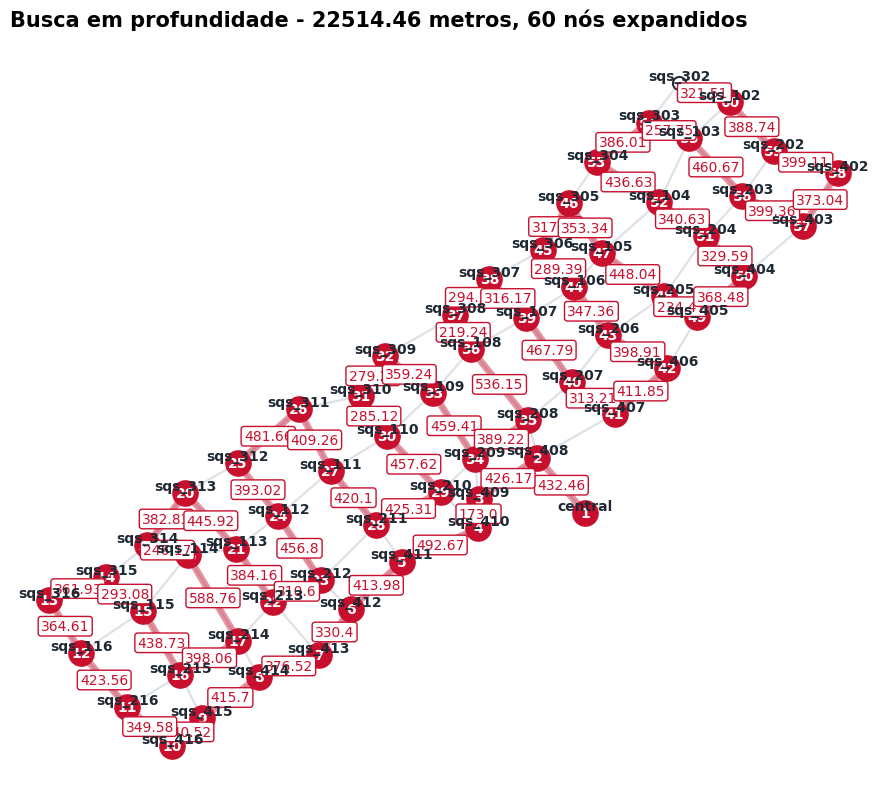

Ordem de expansão dos nós:
 1: central |  2: sqs_408 |  3: sqs_407 |  4: sqs_208 |  5: sqs_409 |  6: sqs_406 |  7: sqs_207 | 
 8: sqs_108 |  9: sqs_209 | 10: sqs_410 | 11: sqs_405 | 12: sqs_206 | 13: sqs_107 | 14: sqs_308 | 
15: sqs_109 | 16: sqs_210 | 17: sqs_411 | 18: sqs_404 | 19: sqs_205 | 20: sqs_106 | 21: sqs_307 | 
22: sqs_309 | 23: sqs_110 | 24: sqs_211 | 25: sqs_412 | 26: sqs_403 | 27: sqs_204 | 28: sqs_105 | 
29: sqs_306 | 30: sqs_310 | 31: sqs_111 | 32: sqs_212 | 33: sqs_413 | 34: sqs_402 | 35: sqs_203 | 
36: sqs_104 | 37: sqs_305 | 38: sqs_311 | 39: sqs_112 | 40: sqs_213 | 41: sqs_414 | 42: sqs_202 | 
43: sqs_103 | 44: sqs_304 | 45: sqs_312 | 46: sqs_113 | 47: sqs_214 | 48: sqs_415 | 49: sqs_102 | 
50: sqs_303 | 51: sqs_313 | 52: sqs_114 | 53: sqs_215 | 54: sqs_416 | 

In [ ]:
if cam_dfs:
    desenhar_mapa(
        caminho=cam_dfs,
        expandidos=ordem_dfs,
        titulo=f"Busca em profundidade - {custo_dfs:.2f} metros, {exp_dfs} nós expandidos",
    )

print("Ordem de expansão dos nós:")
for count, n in enumerate(ordem_bfs, start=1):
    print(f"{count:2d}: {n} |", end=" ")
    if count % 7 == 0:
        print()

# **BUSCAS COM HEURÍSTICAS**

Neste momento, as buscas simples são deixadas pra trás e começamos a testar as buscas com heurísticas.
* Busca Gulosa;
* Busca A*.

#**DEFINIÇÃO DA HEURÍSTICA**

A Heurística utilizada aqui é a distância em linha reta da central de distribuição até a quadra escolhida.

In [ ]:
HSLD = {}

for quadras in COORD:
    HSLD[quadras] = round(obter_distancia(quadras, "central"), 2)


# Verificação de sanidade: toda cidade do mapa tem valor de heurística?
faltando = [c for c in MAPA if c not in HSLD]
print("Quadras sem heurística:", faltando if faltando else "nenhuma")

# O objetivo precisa ter h = 0: quando chegamos, não falta mais nada.
print("h(central) =", HSLD["central"], "- tem que ser zero")
print()

print("Algumas leituras:")
for quadra in ["sqs_102", "sqs_212", "sqs_306", "sqs_410"]:
    print(f"  h({quadra:6s}) = {HSLD[quadra]:.2f} m em linha reta")

Quadras sem heurística: nenhuma
h(central) = 0.0 - tem que ser zero

Algumas leituras:
  h(sqs_102) = 2574.14 m em linha reta
  h(sqs_212) = 1614.34 m em linha reta
  h(sqs_306) = 1574.30 m em linha reta
  h(sqs_410) = 638.66 m em linha reta


#**PROVANDO DE FORMA EMPÍRICA A ADMISSIBILIDADE**

Se em ALGUMA quadra a estimativa for maior que o custo real, a
heurística não é admissível e o A* perde a garantia de otimalidade.

In [ ]:
violacoes = []
linhas_tabela = []

for cidade in sorted(MAPA):
    if cidade == "central":
        continue

    _, custo_real, _, _ = busca_custo_uniforme(cidade, "central")

    estimativa = HSLD[cidade]
    folga = custo_real - estimativa     # quanto a heurística subestimou
    linhas_tabela.append((cidade, estimativa, custo_real, folga))

    if estimativa > custo_real:
        violacoes.append(cidade)

if linhas_tabela:
    print(f"{'DronePorto':18s} {'h(n)':>8s} {'h*(n)':>8s} {'folga':>8s}")
    print("-" * 45)
    # sorted com key=... ordena pela folga, do menor para o maior.
    for cidade, est, real, folga in sorted(linhas_tabela, key=lambda t: t[3]):
        print(f"{cidade:18s} {est:8.2f} {real:9.2f} {folga:8.2f}")

    print()
    if violacoes:
        print("Heurística NÃO admissível. Violações em:", violacoes)
    else:
        print(f"Admissível nas {len(linhas_tabela)} cidades: h nunca superou h*.")
        apertada = min(linhas_tabela, key=lambda t: t[3])
        print(f"Caso mais apertado: {apertada[0]}, com folga de apenas "
              f"{apertada[3]} km.")

DronePorto             h(n)    h*(n)    folga
---------------------------------------------
sqs_408              432.46    432.46     0.00
sqs_208              646.93    663.35    16.42
sqs_108             1180.68   1199.50    18.82
sqs_308             1397.04   1418.74    21.70
sqs_307             1493.79   1713.06   219.27
sqs_409              636.18    858.63   222.45
sqs_207              775.04   1003.94   228.90
sqs_107             1204.66   1471.73   267.07
sqs_206             1058.77   1356.17   297.40
sqs_209              727.63   1052.57   324.94
sqs_407              610.04    956.39   346.35
sqs_109             1144.94   1511.98   367.04
sqs_309             1504.17   1871.22   367.05
sqs_106             1335.53   1703.53   368.00
sqs_406              982.49   1368.24   385.75
sqs_405             1333.50   1719.30   385.80
sqs_410              638.66   1031.63   392.97
sqs_205             1362.45   1757.35   394.90
sqs_404             1686.30   2087.78   401.48
sqs_411        

# **BUSCA GULOSA**

Neste momento, será realizado a primeira busca com heurística.<br>
Ordena a fronteira por h(n).

In [ ]:
def busca_gulosa(inicio, objetivo, h):
    """Ordena a fronteira apenas pela estimativa h(n)."""
    contador = itertools.count()
    fronteira = []
    heapq.heappush(fronteira, (h[inicio], next(contador), No(inicio)))
    explorados = set()
    ordem = []

    while fronteira:
        _, _, no = heapq.heappop(fronteira)

        if no.estado == objetivo:
            return reconstruir_caminho(no), no.g, len(ordem), ordem

        if no.estado in explorados:
            continue

        explorados.add(no.estado)
        ordem.append(no.estado)

        for vizinho, custo in MAPA[no.estado].items():
            if vizinho in explorados:
                continue
            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)
            # A prioridade é SÓ a heurística: o passado é ignorado.
            heapq.heappush(fronteira, (h[vizinho], next(contador), filho))

    return None, None, len(ordem), ordem


cam_gul, custo_gul, exp_gul, ordem_gul = busca_gulosa(inicio, fim, HSLD)

print("Caminho:", " -> ".join(cam_gul))
print(f"Custo: {custo_gul:.2f} metros  |  Nós expandidos: {exp_gul}")
print()
print("Apenas", exp_gul, "expansões")
print(f"E {custo_gul:.2f} metros: o mesmo caminho subótimo da busca em largura.")

Caminho: central -> sqs_408 -> sqs_407 -> sqs_207 -> sqs_206 -> sqs_106 -> sqs_105 -> sqs_305 -> sqs_304 -> sqs_303 -> sqs_302
Custo: 3556.23 metros  |  Nós expandidos: 54

Apenas 54 expansões
E 3556.23 metros: o mesmo caminho subótimo da busca em largura.


#**VISUALIZANDO O QUE A BUSCA GULOSA FEZ**

Para servir de exemplo na comparação com a busca A*.

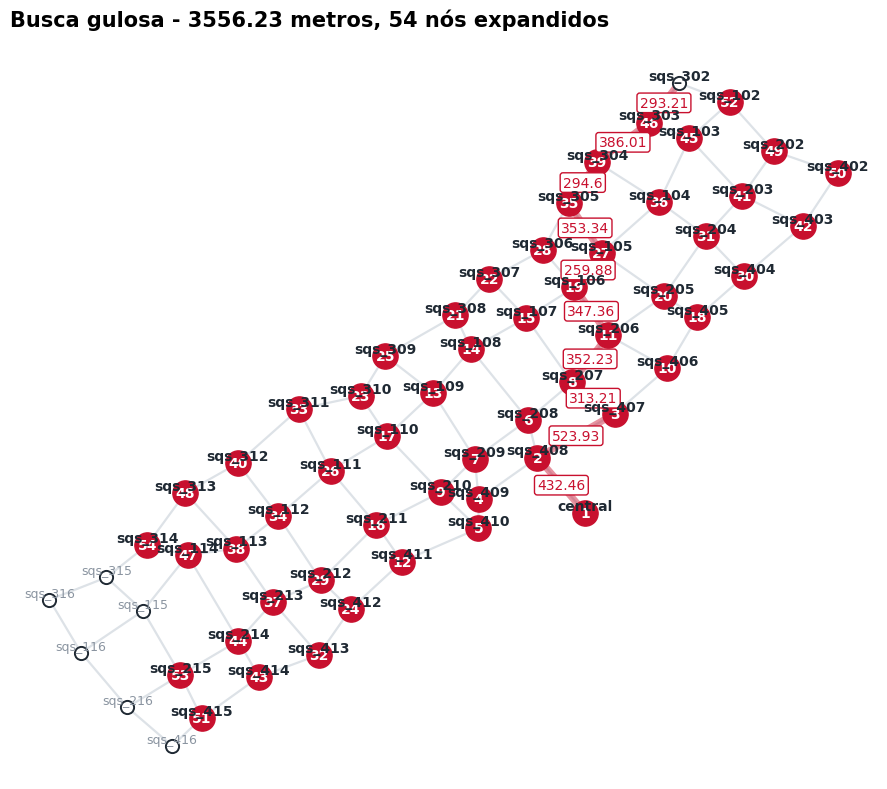

Ordem de expansão dos nós:
 1: central |  2: sqs_408 |  3: sqs_407 |  4: sqs_409 |  5: sqs_410 |  6: sqs_208 |  7: sqs_209 | 
 8: sqs_207 |  9: sqs_210 | 10: sqs_406 | 11: sqs_206 | 12: sqs_411 | 13: sqs_109 | 14: sqs_108 | 
15: sqs_107 | 16: sqs_211 | 17: sqs_110 | 18: sqs_405 | 19: sqs_106 | 20: sqs_205 | 21: sqs_308 | 
22: sqs_307 | 23: sqs_310 | 24: sqs_412 | 25: sqs_309 | 26: sqs_111 | 27: sqs_105 | 28: sqs_306 | 
29: sqs_212 | 30: sqs_404 | 31: sqs_204 | 32: sqs_413 | 33: sqs_311 | 34: sqs_112 | 35: sqs_305 | 
36: sqs_104 | 37: sqs_213 | 38: sqs_113 | 39: sqs_304 | 40: sqs_312 | 41: sqs_203 | 42: sqs_403 | 
43: sqs_414 | 44: sqs_214 | 45: sqs_103 | 46: sqs_303 | 47: sqs_114 | 48: sqs_313 | 49: sqs_202 | 
50: sqs_402 | 51: sqs_415 | 52: sqs_102 | 53: sqs_215 | 54: sqs_314 | 

In [ ]:
if cam_gul:
    desenhar_mapa(
        caminho=cam_gul,
        expandidos=ordem_gul,
        titulo=f"Busca gulosa - {custo_gul:.2f} metros, {exp_gul} nós expandidos",
    )

print("Ordem de expansão dos nós:")
for count, n in enumerate(ordem_gul, start=1):
    print(f"{count:2d}: {n} |", end=" ")
    if count % 7 == 0:
        print()

# BUSCA A*

Chegamos ao ponto final do Marco 1. A busca A*.<br>
Ordena a fronteira por f(n) = g(n) + h(n)

In [ ]:
def a_estrela(inicio, objetivo, h):
    """Ordena a fronteira por f(n) = g(n) + h(n).

    Parâmetros:
        inicio (str): cidade de partida.
        objetivo (str): cidade de destino.
        h (dict): a função heurística, como dicionário cidade -> estimativa.

    Devolve:
        tuple: (caminho, custo, nós expandidos, ordem de expansão).
    """
    contador = itertools.count()
    fronteira = []
    heapq.heappush(fronteira, (h[inicio], next(contador), No(inicio)))
    explorados = set()
    ordem = []

    while fronteira:
        _, _, no = heapq.heappop(fronteira)

        if no.estado == objetivo:
            return reconstruir_caminho(no), no.g, len(ordem), ordem

        if no.estado in explorados:
            continue

        explorados.add(no.estado)
        ordem.append(no.estado)

        for vizinho, custo in MAPA[no.estado].items():
            if vizinho in explorados:
                continue

            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)

            heapq.heappush(fronteira, (filho.g + h[vizinho], next(contador), filho))

    return None, None, len(ordem), ordem


# ------------------- teste automático, não precisa alterar -------------------
cam_ast, custo_ast, exp_ast, ordem_ast = a_estrela(inicio, fim, HSLD)

print(f"Custo: {custo_ast:.2f} metros | Nós expandidos: {exp_ast}")
print(f"\nCaminho: '{cam_ast[0]}' até '{cam_ast[-1]}'")

Custo: 3284.06 metros | Nós expandidos: 53

Caminho: 'central' até 'sqs_302'


#**VISUALIZANDO O QUE A BUSCA A'*' FEZ**

Para servir de exemplo em comparação com a busca gulosa.

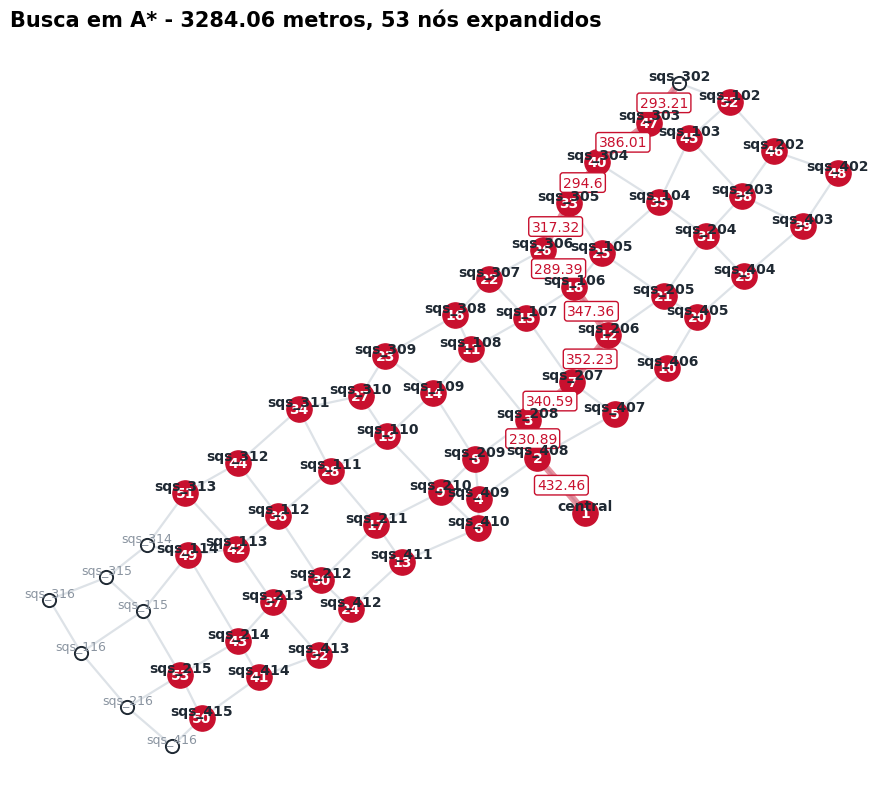

Ordem de expansão dos nós:
 1: central |  2: sqs_408 |  3: sqs_208 |  4: sqs_409 |  5: sqs_407 |  6: sqs_410 |  7: sqs_207 | 
 8: sqs_209 |  9: sqs_210 | 10: sqs_406 | 11: sqs_108 | 12: sqs_206 | 13: sqs_411 | 14: sqs_109 | 
15: sqs_107 | 16: sqs_308 | 17: sqs_211 | 18: sqs_106 | 19: sqs_110 | 20: sqs_405 | 21: sqs_205 | 
22: sqs_307 | 23: sqs_309 | 24: sqs_412 | 25: sqs_105 | 26: sqs_306 | 27: sqs_310 | 28: sqs_111 | 
29: sqs_404 | 30: sqs_212 | 31: sqs_204 | 32: sqs_413 | 33: sqs_305 | 34: sqs_311 | 35: sqs_104 | 
36: sqs_112 | 37: sqs_213 | 38: sqs_203 | 39: sqs_403 | 40: sqs_304 | 41: sqs_414 | 42: sqs_113 | 
43: sqs_214 | 44: sqs_312 | 45: sqs_103 | 46: sqs_202 | 47: sqs_303 | 48: sqs_402 | 49: sqs_114 | 
50: sqs_415 | 51: sqs_313 | 52: sqs_102 | 53: sqs_215 | 

In [ ]:
if cam_ast:
    desenhar_mapa(
        caminho=cam_ast,
        expandidos=ordem_ast,
        titulo=f"Busca em A* - {custo_ast:.2f} metros, {exp_ast} nós expandidos",
    )

print("Ordem de expansão dos nós:")
for count, n in enumerate(ordem_ast, start=1):
    print(f"{count:2d}: {n} |", end=" ")
    if count % 7 == 0:
        print()

In [ ]:
# ---------------------------------------------------------------------
# Abrindo f = g + h em cada passo do caminho encontrado pelo A*.
# ---------------------------------------------------------------------

if cam_ast:
    print(f"{'DronePorto':18s} {'g':>9s} {'h':>9s} {'f = g+h':>9s}")
    print("-" * 47)

    g_acumulado = 0
    valores_f = []

    # enumerate() devolve (índice, item); usamos o índice para pegar a
    # cidade anterior e somar o custo do trecho.
    for i, cidade in enumerate(cam_ast):
        if i > 0:
            g_acumulado += MAPA[cam_ast[i - 1]][cidade]
        f = g_acumulado + HSLD[cidade]
        valores_f.append(f)
        print(f"{cidade:20s} {g_acumulado:8.2f} {HSLD[cidade]:8.2f} {f:9.2f}")

    print()
    print("Sequência de f:", " -> ".join(str(round(v, 2)) for v in valores_f))

    # all() devolve True se TODAS as comparações forem verdadeiras.
    nao_decresce = all(a <= b for a, b in zip(valores_f, valores_f[1:]))
    print("f nunca diminuiu?", "sim" if nao_decresce else "NÃO")
    print("No objetivo, h = 0, portanto f = g =", valores_f[-1], "metros")

DronePorto                 g         h   f = g+h
-----------------------------------------------
central                  0.00     0.00      0.00
sqs_408                432.46   432.46    864.92
sqs_208                663.35   646.93   1310.28
sqs_207               1003.94   775.04   1778.98
sqs_206               1356.17  1058.77   2414.94
sqs_106               1703.53  1335.53   3039.06
sqs_306               1992.92  1574.30   3567.22
sqs_305               2310.24  1834.67   4144.91
sqs_304               2604.84  2075.15   4679.99
sqs_303               2990.85  2338.43   5329.28
sqs_302               3284.06  2600.69   5884.75

Sequência de f: 0.0 -> 864.92 -> 1310.28 -> 1778.98 -> 2414.94 -> 3039.06 -> 3567.22 -> 4144.91 -> 4679.99 -> 5329.28 -> 5884.75
f nunca diminuiu? sim
No objetivo, h = 0, portanto f = g = 5884.75 metros


In [ ]:
# ---------------------------------------------------------------------
# PAINEL COMPARATIVO — os cinco algoritmos sobre o mesmo problema.
# ---------------------------------------------------------------------

import pandas as pd

# Criar instâncias de Drone e Clima para o painel comparativo
# Usaremos valores padrão ou representativos para a comparação.
# Você pode ajustar esses valores conforme desejar para os testes comparativos.
comparative_drone = Drone(carga=2.0, velocidade=80) # Exemplo de drone padrão
comparative_clima = Clima(vento_vel=0, vento_dir=0, chuva=0.0, tempestade=False) # Exemplo de clima padrão

algoritmos = [
    ("Profundidade", busca_profundidade, False),
    ("Largura", busca_largura, False),
    ("Custo uniforme", busca_custo_uniforme, False),
    ("Gulosa", busca_gulosa, True),
    ("A*", a_estrela, True), # A* agora requer drone e clima
]

linhas_painel = []
for nome, funcao, usa_h in algoritmos:
    if nome == "A*": # Tratamento especial para A* que agora exige drone e clima
        caminho, custo, expandidos, _ = funcao(inicio, fim, HSLD, comparative_drone, comparative_clima)
    elif usa_h:
        caminho, custo, expandidos, _ = funcao(inicio, fim, HSLD)
    else:
        caminho, custo, expandidos, _ = funcao(inicio, fim)

    linhas_painel.append({
        "algoritmo": nome,
        "custo_m": custo,
        "nos_expandidos": expandidos,
        "cidades_no_caminho": len(caminho),
        "otimo": "sim" if custo < 3500 else "não",
    })

if linhas_painel:
    painel = pd.DataFrame(linhas_painel)
    print(painel.to_string(index=False))


NameError: name 'Drone' is not defined

In [ ]:
# ---------------------------------------------------------------------
# GRÁFICO COMPARATIVO — qualidade e esforço, lado a lado.
# ---------------------------------------------------------------------

if linhas_painel:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    # As cores saem do painel, para o gráfico continuar correto mesmo
    # que algum TODO ainda esteja em branco.
    paleta = {"Profundidade": "#9A6700", "Largura": "#1E4E79",
              "Custo uniforme": "#1B7F5A", "Gulosa": "#5A6570", "A*": "#C8102E"}
    nomes = list(painel["algoritmo"])
    cores = [paleta[a] for a in nomes]

    b1 = ax1.bar(nomes, painel["custo_m"], color=cores)
    ax1.axhline(3284, color="#C8102E", ls="--", lw=1.5)
    ax1.set_title("Custo do caminho encontrado", fontsize=13, fontweight="bold")
    ax1.set_ylabel("metros")
    ax1.bar_label(b1, fmt="%d km", fontsize=11, padding=3)
    ax1.set_ylim(0, 25000)

    b2 = ax2.bar(nomes, painel["nos_expandidos"], color=cores)
    ax2.set_title("Esforço: nós expandidos", fontsize=13, fontweight="bold")
    ax2.set_ylabel("nós")
    ax2.bar_label(b2, fontsize=11, padding=3)
    ax2.set_ylim(0, 70)

    for eixo in (ax1, ax2):
        eixo.spines["top"].set_visible(False)
        eixo.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

NameError: name 'linhas_painel' is not defined

In [ ]:
# ---------------------------------------------------------------------
# Teste do A* para outras rotas
# ---------------------------------------------------------------------

pares = [
    ("central", "sqs_102"), ("central", "sqs_112"), ("central", "sqs_202"),
    ("central", "sqs_212"), ("central", "sqs_302"), ("central", "sqs_312"),
]

resultados = []

# Criar instâncias de Drone e Clima para este painel de testes
# Você pode ajustar esses valores conforme desejar para os testes.
test_drone = Drone(carga=2.0, velocidade=80) # Exemplo de drone padrão
test_clima = Clima(vento_vel=0, vento_dir=0, chuva=0.0, tempestade=False) # Exemplo de clima padrão

for origem, destino in pares:
    _, custo_u, exp_u, _ = busca_custo_uniforme(origem, destino)
    # Agora passando os objetos drone e clima para a_estrela
    _, custo_a, exp_a, _ = a_estrela(origem, destino, HSLD, test_drone, test_clima)

    if custo_u is None or custo_a is None:
        print("Complete os TODOs 3 e 4 antes de rodar o experimento.")
        break

    resultados.append({
        "rota": f"{origem} -> {destino}",
        "custo_uniforme": custo_u,
        "custo_a_estrela": custo_a,
        "mesmo_custo": "sim" if custo_u == custo_a else "NÃO",
        "nos_uniforme": exp_u,
        "nos_a_estrela": exp_a,
        "economia_esforco": f"{(1 - exp_a / exp_u) * 100:.0f}%",
    })

if resultados:
    tabela = pd.DataFrame(resultados)
    print(tabela.to_string(index=False))
    print()

    # Verificação central: o A* achou o ótimo em TODAS as rotas?
    todos_otimos = all(r["mesmo_custo"] == "sim" for r in resultados)
    print("O A* devolveu o custo ótimo em todas as rotas?",
          "sim" if todos_otimos else "NÃO")

    media = sum(int(r["economia_esforco"].rstrip("%")) for r in resultados)
    print(f"Economia média de nós expandidos: {media / len(resultados):.0f}%")


### Códigos que vamos tentar implementar para trazer uma complexidade



In [ ]:
# Modelagem da Física, Carga e Clima

import math

# Altura de decolagem/pouso fixada conforme requisito
ALTITUDE_CRUZEIRO = 25 # metros
CUSTO_ENERGIA_VERTICAL = 10 # Gasto arbitrário de energia para subir/descer 25m

class Clima:
    def __init__(self, vento_vel, vento_dir, chuva, tempestade):
        self.vento_vel = vento_vel   # km/h
        self.vento_dir = vento_dir   # graus (0 a 360, direção para onde o vento sopra)
        self.chuva = chuva           # 0.0 (sem chuva) a 1.0 (chuva forte)
        self.tempestade = tempestade # Booleano (True impede o voo)

class Drone:
    def __init__(self, carga, velocidade):
        # Limita a carga até 5kg e velocidade entre 50 e 104 km/h
        self.carga = max(0.0, min(5.0, carga))
        self.velocidade = max(50.0, min(104.0, velocidade))

In [ ]:
# Motor de Custo Dinâmico (Arestas Assimétricas)

def calcular_custo_energetico(u, v, drone, clima):
    # Regra 3: Tempestades causam bloqueio absoluto (custo infinito)
    if clima.tempestade:
        return float('inf')

    # Coleta coordenadas
    x1, y1 = coords[u]
    x2, y2 = coords[v]

    # Distância 2D em metros
    dx = x2 - x1
    dy = y2 - y1
    distancia_m = math.hypot(dx, dy)

    # ----- CÁLCULO DO VENTO (VETOR) -----
    # Ângulo do voo de u para v
    angulo_voo = math.degrees(math.atan2(dy, dx))

    # Diferença entre a direção do vento e a direção do voo
    diferenca_angulo = math.radians(clima.vento_dir - angulo_voo)

    # Projeção do vento na direção do voo (positivo = a favor, negativo = contra)
    vento_efetivo = math.cos(diferenca_angulo) * clima.vento_vel

    # Velocidade real em relação ao solo (km/h)
    velocidade_solo = drone.velocidade + vento_efetivo
    if velocidade_solo <= 5:
        velocidade_solo = 5 # Evita velocidade nula se o vento for muito forte contra

    # ----- CÁLCULO DE CONSUMO (FÍSICA E CARGA) -----
    # Tempo de voo neste trecho (em horas)
    tempo_horas = (distancia_m / 1000) / velocidade_solo

    # Multiplicadores de penalidade
    penalidade_carga = 1 + (drone.carga * 0.15) # Ex: 5kg aumenta consumo em 75%
    penalidade_chuva = 1 + (clima.chuva * 0.30) # Chuva aumenta arrasto em até 30%

    # Consumo base arbitrário (ex: 100 unidades de energia por hora)
    consumo_base_hora = 100

    # Custo final da aresta em unidades de energia
    energia_gasta = tempo_horas * consumo_base_hora * penalidade_carga * penalidade_chuva

    return energia_gasta

In [ ]:
# Integração das 3 Etapas de Voo (O Espaço de Busca)

def executar_missao_drone(origem, destino, drone, clima):
    print(f"--- Iniciando Missão: {origem} -> {destino} ---")
    print(f"Carga: {drone.carga}kg | Velocidade: {drone.velocidade}km/h")

    if clima.tempestade:
        print("MISSÃO ABORTADA: Tempestade detectada na região.")
        return None

    # Etapa 1: Decolagem (0 a 25m)
    energia_total = CUSTO_ENERGIA_VERTICAL
    print("1. Decolagem para 25m concluída.")

    # Etapa 2: Cruzeiro 2D - Usando o algoritmo A* modificado com custo dinâmico
    print("2. Calculando rota de cruzeiro 2D usando A* com custos dinâmicos...")
    # Chama o A* passando HSLD (heurística em metros), o objeto drone e o objeto clima
    cam_ast, custo_ast, nos_expandidos, ordem_expansao = a_estrela(origem, destino, HSLD, drone, clima)

    if not cam_ast:
        print("Não foi possível encontrar uma rota para o cruzeiro 2D.")
        return None

    energia_cruzeiro = custo_ast # O custo retornado pelo A* agora é o custo total de energia

    energia_total += energia_cruzeiro
    print(f"2. Cruzeiro 2D concluído. Caminho: {' -> '.join(cam_ast)}")

    # Etapa 3: Pouso (25m a 0)
    energia_total += CUSTO_ENERGIA_VERTICAL
    print("3. Pouso concluído.")

    print(f"-> Energia Total Consumida: {energia_total:.2f} unidades\n")
    return cam_ast, energia_total

# --- Testando a Implementação ---
# Drone e condições climáticas de exemplo
meu_drone = Drone(carga=3.4, velocidade=104) # Drone pesado e rápido
meu_clima = Clima(vento_vel=15, vento_dir=90, chuva=0.5, tempestade=False) # Vento leste, chuva média

# Teste 1: Rota padrão com condições moderadas
executar_missao_drone("sqs_105", "sqs_207", meu_drone, meu_clima)

# Teste 2: Com drone mais pesado e vento contra
print("\n--- Teste com drone mais pesado e vento contra (de leste) ---\n")
drone_pesado = Drone(carga=5.0, velocidade=80)
clima_vento_contra = Clima(vento_vel=30, vento_dir=90, chuva=0.2, tempestade=False) # Vento forte de leste (90 graus)
executar_missao_drone("sqs_105", "sqs_207", drone_pesado, clima_vento_contra)

# Teste 3: Com tempestade (deve abortar)
print("\n--- Teste com tempestade ---\n")
clima_tempestade = Clima(vento_vel=10, vento_dir=0, chuva=0.1, tempestade=True) # Tempestade impede voo
executar_missao_drone("sqs_105", "sqs_207", meu_drone, clima_tempestade)
